In [80]:
from bs4 import BeautifulSoup
import requests
import pandas as pd
import matplotlib .pyplot as plt

In [81]:
url = 'https://quotes.toscrape.com/'
response = requests.get(url)
soup = BeautifulSoup(response.text,"html.parser")
print(response.status_code)
print(response.text)
print(soup.title.text)

200
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<title>Quotes to Scrape</title>
    <link rel="stylesheet" href="/static/bootstrap.min.css">
    <link rel="stylesheet" href="/static/main.css">
    
    
</head>
<body>
    <div class="container">
        <div class="row header-box">
            <div class="col-md-8">
                <h1>
                    <a href="/" style="text-decoration: none">Quotes to Scrape</a>
                </h1>
            </div>
            <div class="col-md-4">
                <p>
                
                    <a href="/login">Login</a>
                
                </p>
            </div>
        </div>
    

<div class="row">
    <div class="col-md-8">

    <div class="quote" itemscope itemtype="http://schema.org/CreativeWork">
        <span class="text" itemprop="text">“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”</span>
        <span>by <small class="

In [83]:
print(soup.title.text)

Quotes to Scrape


In [84]:
quotes = soup.find_all("div", class_="quote")
for quote in quotes:
   text = quote.find("span", class_="text").text
   author = quote.find("small", class_="author").text
   tags = quote.find_all("a", class_="tag")
   tag_names = [tag.text for tag in tags]
   print("Quote:", text)
   print("Author:", author)
   print("Tags:", tag_names)
   print("-"*50)

Quote: “The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
Author: Albert Einstein
Tags: ['change', 'deep-thoughts', 'thinking', 'world']
--------------------------------------------------
Quote: “It is our choices, Harry, that show what we truly are, far more than our abilities.”
Author: J.K. Rowling
Tags: ['abilities', 'choices']
--------------------------------------------------
Quote: “There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”
Author: Albert Einstein
Tags: ['inspirational', 'life', 'live', 'miracle', 'miracles']
--------------------------------------------------
Quote: “The person, be it gentleman or lady, who has not pleasure in a good novel, must be intolerably stupid.”
Author: Jane Austen
Tags: ['aliteracy', 'books', 'classic', 'humor']
--------------------------------------------------
Quote: “Imperfection is beauty, madness is

In [85]:
data = []
for quote in quotes:
    text = quote.find("span", class_="text").get_text(strip=True)
    author = quote.find("small", class_="author").get_text(strip=True)
    tags = [
         tag.get_text(strip=True)
         for tag in quote.find_all("a", class_="tag")
    ]
    dict = {
        "text":text,
        "author":author,
        "tags" : tags
    }
    data.append(dict)
    print(data[:2])
    print("Total records:", len(data))

[{'text': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'author': 'Albert Einstein', 'tags': ['change', 'deep-thoughts', 'thinking', 'world']}]
Total records: 1
[{'text': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'author': 'Albert Einstein', 'tags': ['change', 'deep-thoughts', 'thinking', 'world']}, {'text': '“It is our choices, Harry, that show what we truly are, far more than our abilities.”', 'author': 'J.K. Rowling', 'tags': ['abilities', 'choices']}]
Total records: 2
[{'text': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'author': 'Albert Einstein', 'tags': ['change', 'deep-thoughts', 'thinking', 'world']}, {'text': '“It is our choices, Harry, that show what we truly are, far more than our abilities.”', 'author': 'J.K. Rowling', 'tags': ['abilities', 'choices']

In [86]:
df = pd.DataFrame(data)
print(df.head())
print(df.shape)

                                                text           author  \
0  “The world as we have created it is a process ...  Albert Einstein   
1  “It is our choices, Harry, that show what we t...     J.K. Rowling   
2  “There are only two ways to live your life. On...  Albert Einstein   
3  “The person, be it gentleman or lady, who has ...      Jane Austen   
4  “Imperfection is beauty, madness is genius and...   Marilyn Monroe   

                                             tags  
0        [change, deep-thoughts, thinking, world]  
1                            [abilities, choices]  
2  [inspirational, life, live, miracle, miracles]  
3              [aliteracy, books, classic, humor]  
4                    [be-yourself, inspirational]  
(10, 3)


In [87]:
df.to_csv("quotes.csv", index=False, encoding="utf-8-sig")
print("CSV file saved successfully!")

CSV file saved successfully!


In [88]:
import os
print(os.getcwd())
print(os.path.exists("quotes.csv"))

C:\Users\Admin\Desktop\Data science Course
True


In [89]:
df_check = pd.read_csv("quotes.csv")
print(df_check.head())
print("Rows and Columns:", df_check.shape)

                                                text           author  \
0  “The world as we have created it is a process ...  Albert Einstein   
1  “It is our choices, Harry, that show what we t...     J.K. Rowling   
2  “There are only two ways to live your life. On...  Albert Einstein   
3  “The person, be it gentleman or lady, who has ...      Jane Austen   
4  “Imperfection is beauty, madness is genius and...   Marilyn Monroe   

                                                tags  
0   ['change', 'deep-thoughts', 'thinking', 'world']  
1                           ['abilities', 'choices']  
2  ['inspirational', 'life', 'live', 'miracle', '...  
3         ['aliteracy', 'books', 'classic', 'humor']  
4                   ['be-yourself', 'inspirational']  
Rows and Columns: (10, 3)


In [90]:
next_button = soup.select_one("li.next a")
print(next_button)
print(next_button["href"])

<a href="/page/2/">Next <span aria-hidden="true">→</span></a>
/page/2/


In [91]:

import pandas as pd

df = pd.read_csv("quotes.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())


                                                text           author  \
0  “The world as we have created it is a process ...  Albert Einstein   
1  “It is our choices, Harry, that show what we t...     J.K. Rowling   
2  “There are only two ways to live your life. On...  Albert Einstein   
3  “The person, be it gentleman or lady, who has ...      Jane Austen   
4  “Imperfection is beauty, madness is genius and...   Marilyn Monroe   

                                                tags  
0   ['change', 'deep-thoughts', 'thinking', 'world']  
1                           ['abilities', 'choices']  
2  ['inspirational', 'life', 'live', 'miracle', '...  
3         ['aliteracy', 'books', 'classic', 'humor']  
4                   ['be-yourself', 'inspirational']  
Dataset shape: (10, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10 non-null     object

10
8


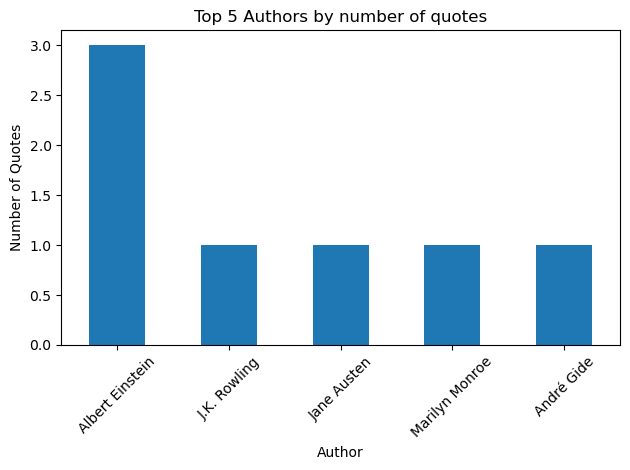

In [92]:
print(len(quotes))
print(df["author"].nunique())
top_authors = df["author"].value_counts().head(5)
top_authors.plot(kind="bar")
plt.title("Top 5 Authors by number of quotes")
plt.xlabel("Author")
plt.ylabel("Number of Quotes")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [93]:
all_tag = df["tags"].dropna().str.split(",").explode()
common_tag = all_tag.value_counts().head(10)
print(common_tag)

tags
['change'                              1
 'deep-thoughts'                       1
 'obvious'                             1
['humor'                               1
['misattributed-eleanor-roosevelt']    1
 'paraphrased']                        1
 'inspirational'                       1
 'failure'                             1
['edison'                              1
 'love']                               1
Name: count, dtype: int64


In [94]:

print(df.columns.tolist())

['text', 'author', 'tags']


In [95]:
duplicates = df[df["text"].duplicated()]
print(duplicates)

Empty DataFrame
Columns: [text, author, tags]
Index: []


In [ ]:

import requests
import pandas as pd
import logging
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)

base_url = "https://quotes.toscrape.com/"
url = base_url
data = []
page_number = 1

while url:
    try:
        logging.info(f"Scraping page {page_number}: {url}")

        response = requests.get(url, timeout=15)
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")
        quotes = soup.find_all("div", class_="quote")

        for quote in quotes:
            text = quote.find(
                "span", class_="text"
            ).get_text(strip=True)

            author = quote.find(
                "small", class_="author"
            ).get_text(strip=True)

            tags = [
                tag.get_text(strip=True)
                for tag in quote.find_all("a", class_="tag")
            ]

            data.append({
                "Quote": text,
                "Author": author,
                "Tags": ", ".join(tags)
            })

        next_button = soup.select_one("li.next a")

        if next_button:
            url = urljoin(url, next_button["href"])
            page_number += 1
        else:
            url = None

        time.sleep(1)

    except requests.RequestException as error:
        logging.error(f"Request failed: {error}")
        break

    except AttributeError as error:
        logging.error(f"Unexpected HTML structure: {error}")
        break

df = pd.DataFrame(data)
df.to_csv("quotes_final.csv", index=False, encoding="utf-8-sig")

logging.info(f"Total quotes collected: {len(df)}")
logging.info("Saved results to quotes_final.csv")

INFO: Scraping page 1: https://quotes.toscrape.com/
INFO: Scraping page 2: https://quotes.toscrape.com/page/2/
INFO: Scraping page 3: https://quotes.toscrape.com/page/3/
INFO: Scraping page 4: https://quotes.toscrape.com/page/4/
INFO: Scraping page 5: https://quotes.toscrape.com/page/5/
INFO: Scraping page 6: https://quotes.toscrape.com/page/6/
INFO: Scraping page 7: https://quotes.toscrape.com/page/7/
INFO: Scraping page 8: https://quotes.toscrape.com/page/8/
INFO: Scraping page 9: https://quotes.toscrape.com/page/9/
INFO: Scraping page 10: https://quotes.toscrape.com/page/10/
